# Independent acceptance and submission evidence

The report evaluates a frozen logistic model on a new simulated fleet in 2027–2031. Acceptance requires event recall ≥80%, overall and per-batch alert rates ≤5%, and at least 100 removal events. The illustrated submission report is in `reports/final_report.md`.

Development data use availability-filtered current and rolling features, connected aircraft/component groups, separate calibration, and policy labels available before 2025-09-01. Four model candidates share the same development partitions and alert rules.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
report = root / 'reports/corrected_v2'
metrics = json.loads((report / 'test_metrics.json').read_text(encoding='utf-8'))
freeze = json.loads((report / 'freeze_manifest.json').read_text(encoding='utf-8'))
pd.DataFrame([{'candidate': metrics['candidate_id'], 'events': metrics['actual_unscheduled_events'], 'detected': metrics['detected_events'], 'event_recall': metrics['event_recall'], 'alerts_per_100': metrics['alerts_per_100'], 'over_capacity_batches': metrics['over_capacity_batches'], 'sla_met': metrics['sla_met']}])

,candidate,events,detected,event_recall,alerts_per_100,over_capacity_batches,sla_met
0,logistic_unweighted,393,384,0.977099,0.400814,0,True


独立性与产物关联

新旧数据按实际时点和实体逐项核对；特征、模型、策略及执行源码的身份保存在冻结清单与验收记录中。

In [2]:
evidence = metrics['acceptance_evidence']
assert all(value == 0 for value in evidence['entity_intersections'].values())
assert pd.Timestamp(evidence['previous_latest_snapshot']) < pd.Timestamp(evidence['first_snapshot'])
assert pd.Timestamp(evidence['frozen_at_utc']) < pd.Timestamp(evidence['generated_at_utc'])
assert pd.Timestamp(freeze['policy_latest_used_label']) < pd.Timestamp(freeze['policy_selection_cutoff'])
pd.Series(evidence)

protocol_id                                               independent_2027_v1
protocol_sha256             790dde36f3b8815745fb2cc4036857ace2df28eb98a50d...
data_manifest_sha256        c6fcaa307b1328f65edfb83e21968a7848e2d2c6b9fb12...
data_version                                            0.3.0-acceptance-2027
seed                                                                 20261113
generated_at_utc                             2026-11-13T01:25:15.506158+00:00
frozen_at_utc                                2026-11-13T01:25:10.299196+00:00
previous_latest_snapshot                            2026-12-06T00:00:00+00:00
first_snapshot                                      2027-01-04T18:00:00+00:00
last_snapshot                                       2031-12-06T00:00:00+00:00
entity_intersections        {'aircraft_id': 0, 'component_id': 0, 'install...
aircraft                                                                   60
components                                                      

In [3]:
candidates = pd.read_csv(report / 'validation_candidate_metrics.csv')
candidates[['candidate_id', 'event_recall', 'alerts_per_100', 'false_positives_per_100', 'brier_score', 'threshold']]

,candidate_id,event_recall,alerts_per_100,false_positives_per_100,brier_score,threshold
0,logistic_unweighted,1.0,0.543024,0.0,0.006092,0.999592
1,logistic_balanced,1.0,0.584795,0.0,0.004929,0.999818
2,lightgbm_unweighted,1.0,0.626566,0.0,0.002989,0.988066
3,lightgbm_balanced,1.0,0.584795,0.0,0.002835,0.987123


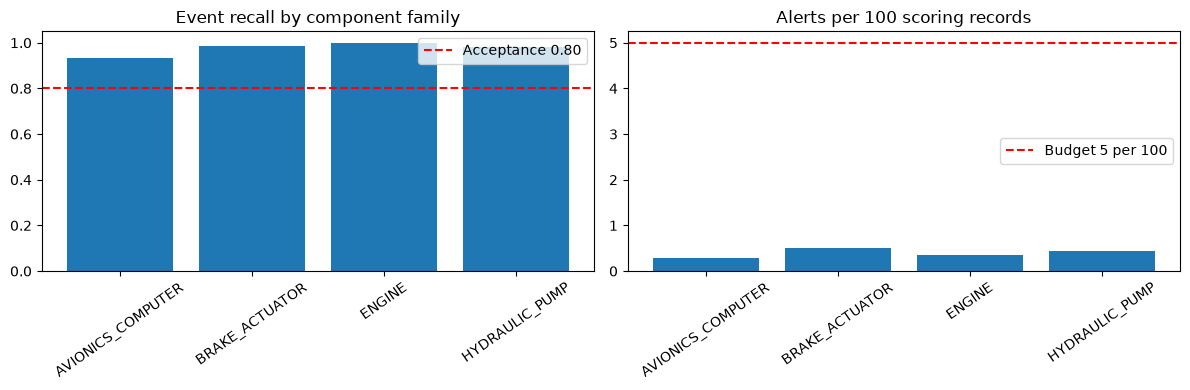

In [4]:
slices = pd.read_csv(report / 'test_slice_metrics.csv')
family = slices[slices.slice_column.eq('component_family')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(family.slice_value, family.event_recall)
axes[0].axhline(.8, color='red', linestyle='--', label='Acceptance 0.80')
axes[0].set(ylim=(0, 1.05), title='Event recall by component family')
axes[0].legend()
axes[1].bar(family.slice_value, family.alerts_per_100)
axes[1].axhline(5, color='red', linestyle='--', label='Budget 5 per 100')
axes[1].set(title='Alerts per 100 scoring records')
axes[1].legend()
for ax in axes:
    ax.tick_params(axis='x', labelrotation=35)
fig.tight_layout()
plt.show()

In [5]:
events = pd.read_csv(report / 'event_detection.csv')
print('Cluster bootstrap:', metrics['bootstrap_95_percent_interval'])
print('Wilson interval assuming independent events:', metrics.get('event_recall_wilson_95_iid_reference'))
print('Missed events:', int((~events.detected).sum()))
events.loc[~events.detected]

Cluster bootstrap: {'event_recall': [0.9626835741080693, 0.9896647486613922], 'alert_rate': [0.003824397124809341, 0.004191560397501574]}
Wilson interval assuming independent events: [0.9570557693309125, 0.9879059821816409]
Missed events: 9


,removal_event_id,detected,component_id,aircraft_id,part_number
28,ACC2027-REM0000038,False,ACC2027-C0000056,ACC2027-AC0005,AVI-C2
64,ACC2027-REM0000082,False,ACC2027-C0000121,ACC2027-AC0010,BRK-D1
88,ACC2027-REM0000110,False,ACC2027-C0000164,ACC2027-AC0014,AVI-C1
125,ACC2027-REM0000154,False,ACC2027-C0000229,ACC2027-AC0019,BRK-D2
220,ACC2027-REM0000267,False,ACC2027-C0000400,ACC2027-AC0034,HYD-B1
261,ACC2027-REM0000314,False,ACC2027-C0000475,ACC2027-AC0041,HYD-B1
328,ACC2027-REM0000394,False,ACC2027-C0000596,ACC2027-AC0051,AVI-C1
334,ACC2027-REM0000402,False,ACC2027-C0000608,ACC2027-AC0052,AVI-C2
388,ACC2027-REM0000468,False,ACC2027-C0000706,ACC2027-AC0060,AVI-C1


结果适用范围

该区间使用新的模拟轨迹和实体，退化机制与开发数据相同。真实机队验证、跨系统批量评分和持续监控需要后续开展。完整结果见 reports/corrected_v2/summary.md。

## Result figures and explanation cases

These figures use saved acceptance predictions and frozen coefficients. Threshold sensitivity in the main report uses validation predictions. The selected model explains raw log-odds through grouped linear contributions; calibrated risk is separate.

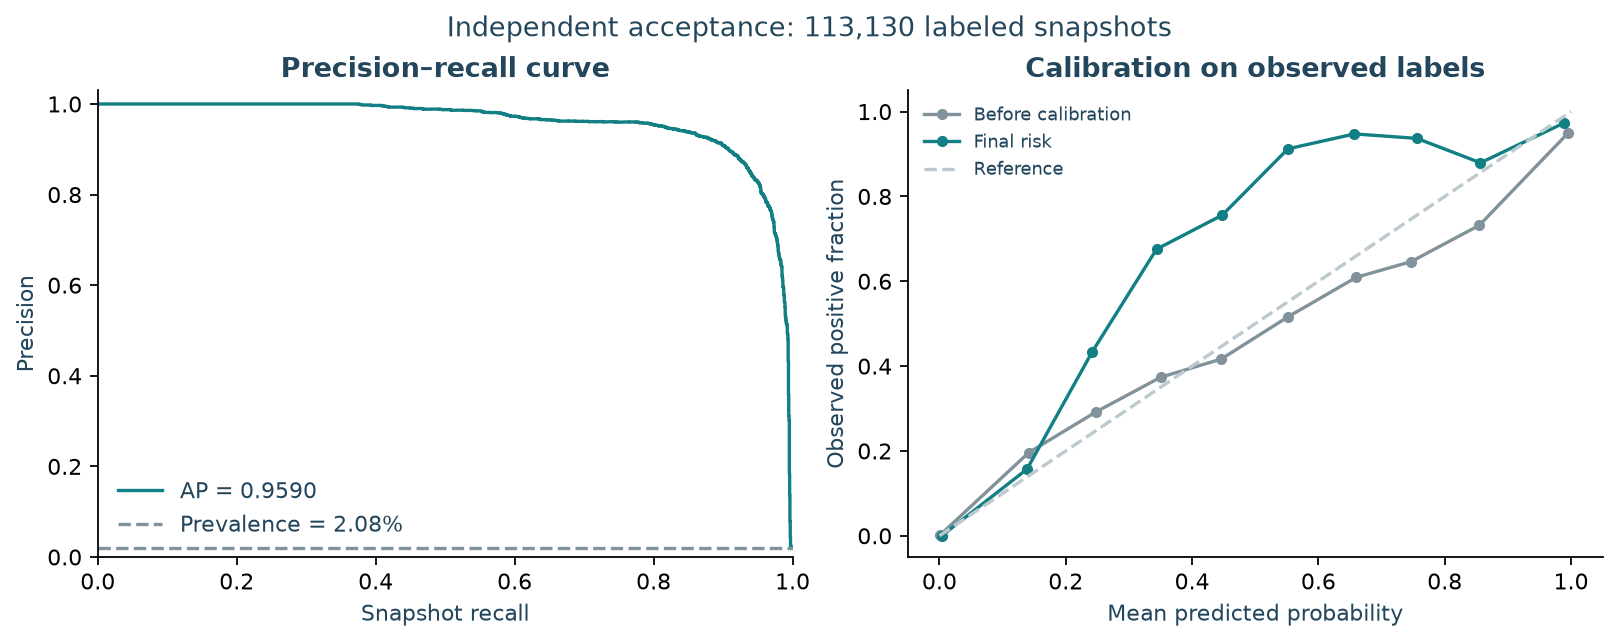

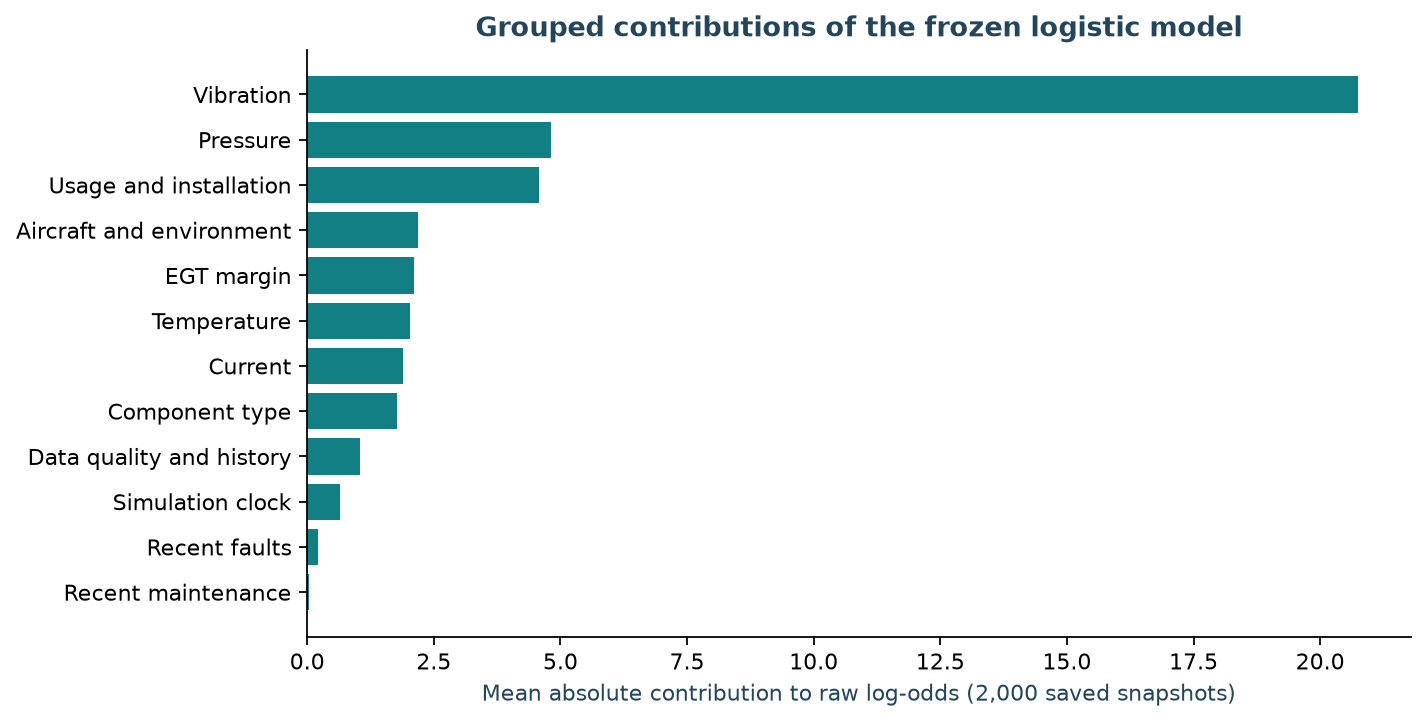

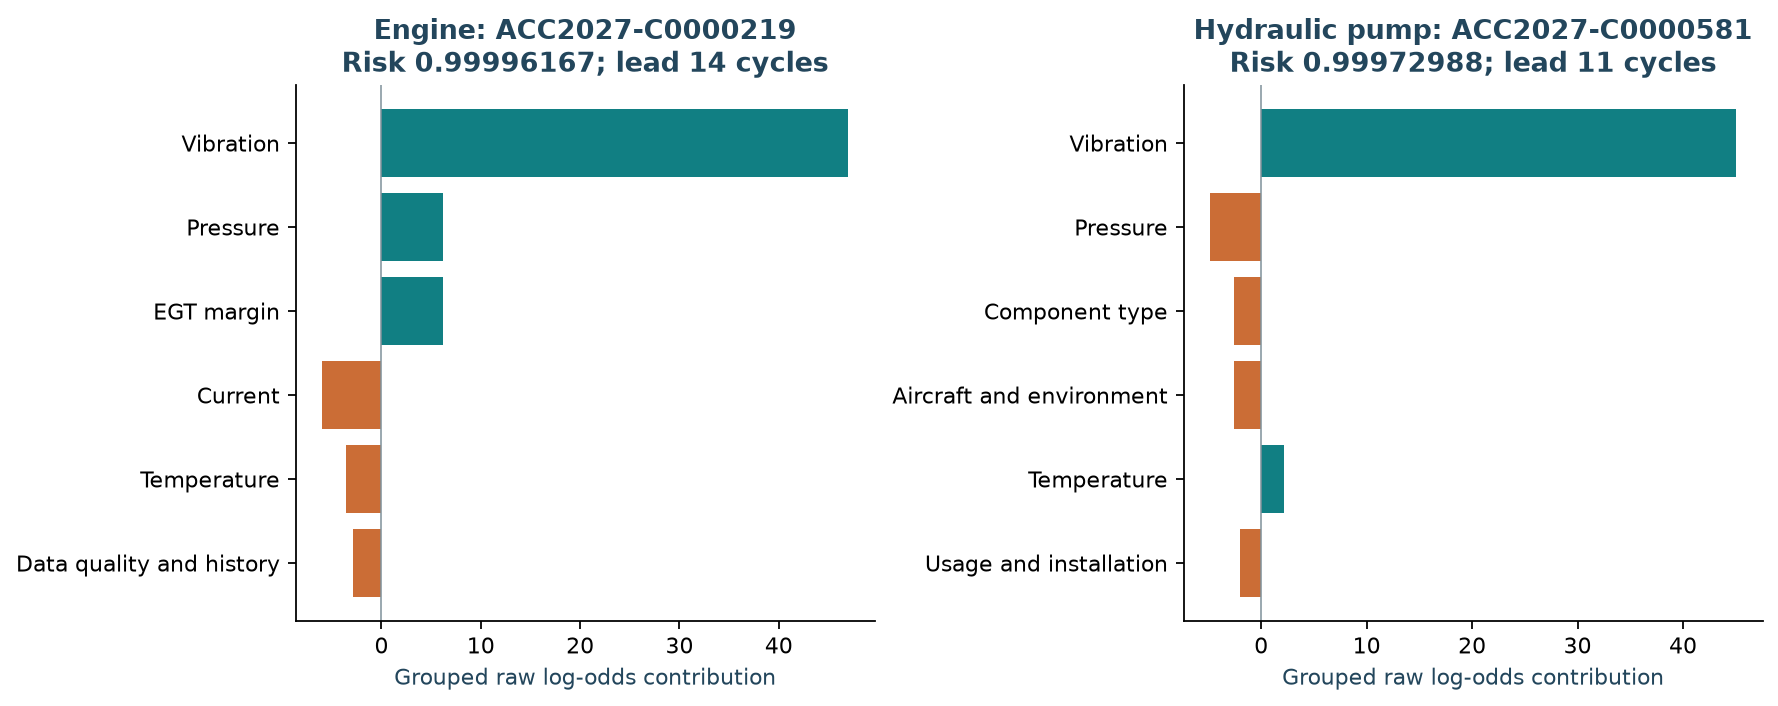

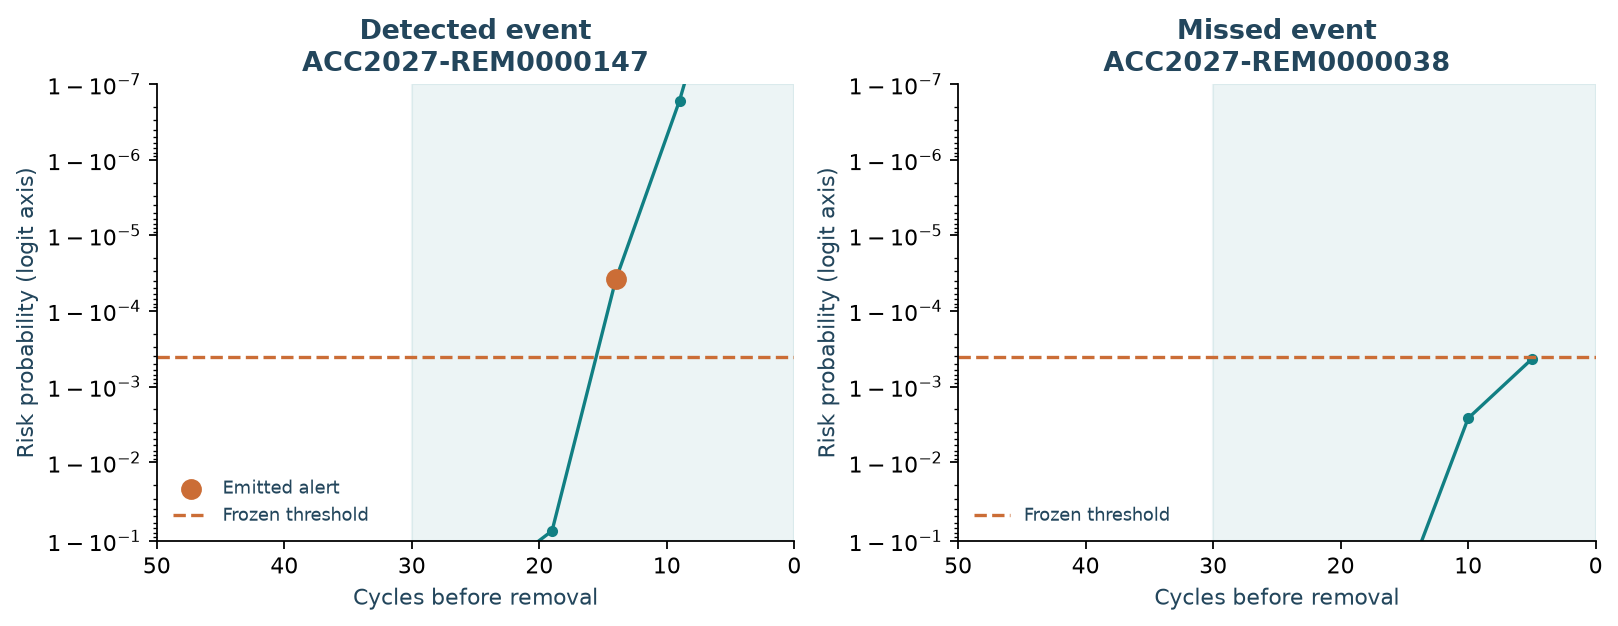

In [6]:
from IPython.display import Image, display
for name in ['ranking_and_calibration.png', 'grouped_contributions.png', 'case_explanations.png', 'detected_and_missed_trajectory.png']:
    display(Image(filename=str(root / 'reports/figures' / name)))

In [7]:
cases = json.loads((root / 'reports/analysis/case_studies.json').read_text(encoding='utf-8'))
pd.DataFrame([{key: value for key, value in case.items() if key != 'group_contributions'} for case in cases])

,component_id,removal_event_id,snapshot_id,family,risk,raw_score,lead_cycles,final_alert
0,ACC2027-C0000219,ACC2027-REM0000147,ACC2027-S00034618,ENGINE,0.999962,32.491220,14.0,True
1,ACC2027-C0000581,ACC2027-REM0000384,ACC2027-S00094516,HYDRAULIC_PUMP,0.999730,26.844315,11.0,True
2,ACC2027-C0000056,ACC2027-REM0000038,ACC2027-S00009100,AVIONICS_COMPUTER,0.999568,25.483274,5.0,False


## Proposed deployment and monitoring

A daily batch service loads a versioned preprocessor, model, calibrator, feature schema and alert policy. Persisted last-alert cycles support suppression across runs. An engineer queue includes risk, reasons, data quality, inspection status and feedback for AMOS/Maximo integration.

Monitor feed delays, missingness, unknown categories, feature/score PSI, alert burden, deferrals, suppression and latency. Once the 30-cycle outcome window and reporting delay mature, monitor event recall, precision, Brier score and lead time by family and time. Review challenger models on a new independent interval and retain the previous package for rollback.

Offline scoring, fallback, PSI and replay are implemented. The service, state store, live queue and release automation are proposed integration work.

## Limitations and next development

The acceptance fleet uses the same synthetic degradation mechanism. The 12 policy events and 14 calibration events constrain threshold and calibration evidence. Nine events were missed, and the earliest warning can be only one cycle before removal. Seventy-seven alerts have censored or pending outcomes. Next work covers real fleet histories, inspection lead time, competing risks, new part numbers and explicit component transfers.